In [230]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import norm

In [400]:
def knots_generation(a,b,K):

    assert K >=2 , "K must be a positive integer."
    assert a < b, "Lower bound a must be less than upper bound b."
    res=np.linspace(a, b, K)
    return res

knots_gen = knots_generation(-10.5, -8, 7)
knots_gen


array([-10.5       , -10.08333333,  -9.66666667,  -9.25      ,
        -8.83333333,  -8.41666667,  -8.        ])

In [401]:
def K_gen(knots):
    knots = np.sort(knots)
    K=len(knots)-1
    Q=np.zeros((K+1,K-1))
    R=np.zeros((K-1,K-1))
    for k in range(K-1):
        h0=knots[k+1]-knots[k]
        h1=knots[k+2]-knots[k+1]
        Q[k,k]=1/h0
        Q[k+1,k]=-1/h0 - 1/h1
        Q[k+2,k]=1/h1
        R[k,k]=(h0+h1)/3
        if k<K-2:
            R[k+1,k]=h1/6
        if k>0:
            R[k-1,k]=h0/6 
    return Q @ np.linalg.solve(R, Q.T)

K_penalty= K_gen(knots_gen)
print(K_penalty)
print("Eigenvalues of K_penalty:", np.linalg.eigvals(K_penalty))
print("Is K_penalty positive definite?", np.all(np.linalg.eigvals(K_penalty) >= -1e-10))  # Allowing for numerical precision issues

[[ 2.22247385e+01 -5.04044308e+01  3.57297231e+01 -9.57046154e+00
   2.55212308e+00 -6.38030769e-01  1.06338462e-01]
 [-5.04044308e+01  1.36538585e+02 -1.31434338e+02  5.74227692e+01
  -1.53127385e+01  3.82818462e+00 -6.38030769e-01]
 [ 3.57297231e+01 -1.31434338e+02  1.93961354e+02 -1.46747077e+02
   6.12509538e+01 -1.53127385e+01  2.55212308e+00]
 [-9.57046154e+00  5.74227692e+01 -1.46747077e+02  1.97789538e+02
  -1.46747077e+02  5.74227692e+01 -9.57046154e+00]
 [ 2.55212308e+00 -1.53127385e+01  6.12509538e+01 -1.46747077e+02
   1.93961354e+02 -1.31434338e+02  3.57297231e+01]
 [-6.38030769e-01  3.82818462e+00 -1.53127385e+01  5.74227692e+01
  -1.31434338e+02  1.36538585e+02 -5.04044308e+01]
 [ 1.06338462e-01 -6.38030769e-01  2.55212308e+00 -9.57046154e+00
   3.57297231e+01 -5.04044308e+01  2.22247385e+01]]
Eigenvalues of K_penalty: [5.15712832e+02 2.63137258e+02 9.69129595e+01 2.44019415e+01
 3.07390063e+00 4.26475578e-14 1.97395589e-15]
Is K_penalty positive definite? True


In [420]:
eigenvalues, eigenvectors = np.linalg.eigh(K_penalty)
coeff = np.random.normal(0, 1, size=7)
eps = np.zeros(7)
for i in range(7):
    if i<=1:
        eps += eigenvectors[:,i]*coeff[i]*0.01
    else:
        eps += eigenvectors[:,i]*coeff[i]/np.sqrt(eigenvalues[i])
eps

array([ 0.43329029, -0.16474258, -0.31343391, -0.17192997, -0.06273661,
        0.11118431,  0.15711285])

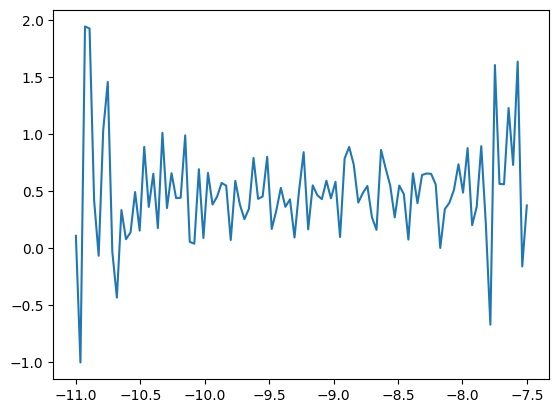

In [384]:
from scipy.interpolate import CubicSpline
def spline(natural_spline, knots, h): 
    # natural_spline = CubicSpline(knots, g, bc_type='natural')

    h_array = np.asarray(h, dtype=float)
    scalar_input = h_array.ndim == 0
    h_array = np.atleast_1d(h_array)

    result = np.empty_like(h_array, dtype=float)

    left_mask = h_array < knots[0]
    right_mask = h_array > knots[-1]
    inside_mask = ~(left_mask | right_mask)

    left_value = natural_spline(knots[0])
    left_slope = natural_spline(knots[0], nu=1)

    right_value = natural_spline(knots[-1])
    right_slope = natural_spline(knots[-1], nu=1)

    result[left_mask] = (
        left_value
        + left_slope * (h_array[left_mask] - knots[0])
    )

    result[right_mask] = (
        right_value
        + right_slope * (h_array[right_mask] - knots[-1])
    )

    result[inside_mask] = natural_spline(h_array[inside_mask])

    if scalar_input:
        return result[0]

    return result

spline_values = [spline(CubicSpline(knots_gen, np.random.rand(len(knots_gen)), bc_type='natural'), knots_gen, h) for h in np.linspace(-11, -7.5, 100)]
plt.plot(np.linspace(-11, -7.5, 100), spline_values)


g.T @ K_penalty @ g: -5.829208643559608e-13


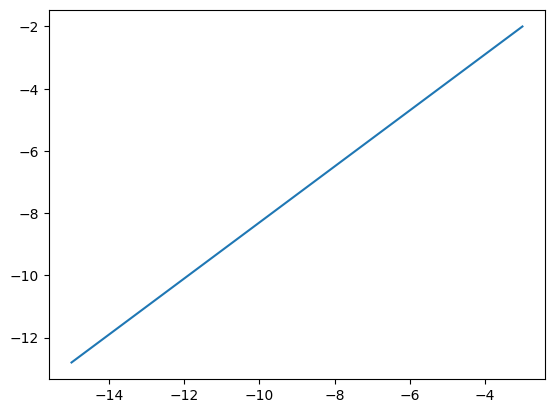

In [370]:
g = 0.7+0.9*knots_gen
spline_func = CubicSpline(knots_gen, g, bc_type='natural')
linear_values = [spline(spline_func, knots_gen, h) for h in np.linspace(-15, -3, 100)]
print("g.T @ K_penalty @ g:", g.T @ K_penalty @ g)
plt.plot(np.linspace(-15, -3, 100), linear_values)


### Equation de rendements

$y_t = \alpha + \beta x_t + \exp(h_t/2) v_t$

avec :

- $\alpha$ : Moyenne des rendements (ex : 0.1, ie 10% de rendements journaliers)
- $x_t \sim \mathcal{U}(-0.05,0.05)$
- $\beta$ : Le coeff de sensibilité du rendement à la variable $x_t$ (ex : 0.9). Augmenter beta augmente la variabilité du rendement observé y.
- $\exp(h_t/2) v_t$ : Composante de vol stochastique avec $v_t \sim \mathcal{N}(0,1)$

### Equation de volatilité 

La forme d'un processus autorégressif linéaire classique est : 

$h_{t+1} = \mu (1-\phi) + \phi h_t + \sigma w_t$

avec :
- $\mu$ : la moyenne à long terme
- $\phi$ : le retour à la moyenne, si $\phi$ proche de 0, on retourne très vite a la moyenne, si $\phi$ proche de 1 on retourne plus lentement
- $w_t \sim \mathcal{N}(0,1)$

Dans notre cas, on remplace $\mu = \mu(h_t) = -10 +1.5 cdf(.)$ => La moyenne dépend de l'état.

- $cdf$ est la fonction de répartition de la loi normale
- Quand la vol est basse (ie $h_t \to -\infty$) cdf tend vers 0 donc la moyenne cible est $\mu(h_t) = -10$
- Quand la vol est haute (ie $h_t \to \infty$) cdf tend vers 1 donc la moyenne cible est $\mu(h_t) = -10+1.5 = -8.5$
- Au numérateur de la cdf, on a $h_t - (-9.25)$ donc quand la vol vaut -9.25, on a cdf(0) = 0.5 donc $\mu(-9.25) = 10+1.5\times 0.5 = -9.25$
- Au dénominateur de la cdf, on a $ 0.5 \sigma / \sqrt{(1-\phi ^2)}$
    - Pour un processus AR(1) stationnaire : $h_{t+1} = c + \phi h_t + \sigma Z_t$, la variance est $Var(h_t) = \dfrac{\sigma ^2}{1-\phi^2}$ donc $\sigma_h = \dfrac{\sigma}{\sqrt{1-\phi^2}}$ 
    - On multiplie par 0.5 pour que la variable d'entrée de la cdf soit adimensionnelle

In [371]:
def mh_simu(h_prev,sigma_w=0.25, phi=0.7,mu=-9.25):
    sigma_h = sigma_w/np.sqrt(1-phi**2)
    scale = 0.5 * sigma_h
    cdf_arg = (h_prev - mu)/scale
    mu_h = -10 + 1.5*norm.cdf(cdf_arg)
    h = mu_h*(1-phi) + phi*h_prev + np.random.normal(0,1)*sigma_w

    return h

In [372]:
def mh_spline(h_prev,sigma_w=0.25, phi=0.7,mu=-9.25,knots=knots_gen):
    sigma_h = sigma_w/np.sqrt(1-phi**2)
    scale = 0.5 * sigma_h
    cdf_arg = (knots - mu)/scale
    mu_h = -10 + 1.5*norm.cdf(cdf_arg)
    g = mu_h*(1-phi) + phi*knots 
    spline_func = CubicSpline(knots, g, bc_type='natural')

    return spline(spline_func, knots, h_prev)

g.T @ K_penalty @ g: 5.167685626805696e-06


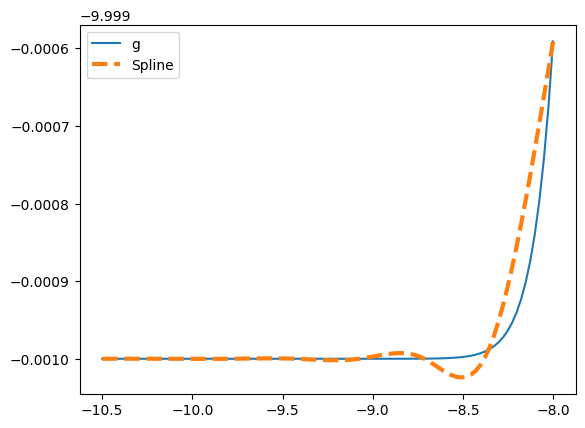

In [373]:
grid = np.linspace(-10.5, -8, 100)
g = -10 + 1.5 * norm.cdf(
    (grid - (-9.25)) / (0.5 * (0.25 / np.sqrt(1 - 0.7**2))) * (1 - 0.7) + 0.7*grid
)

g_at_knots = -10 + 1.5 * norm.cdf(
    (knots_gen - (-9.25)) / (0.5 * (0.25 / np.sqrt(1 - 0.7**2))) * (1 - 0.7) + 0.7*knots_gen
)
spline_func = CubicSpline(knots_gen, g_at_knots, bc_type='natural')
spline_values = [spline(spline_func, knots_gen, h) for h in grid]

print("g.T @ K_penalty @ g:", g_at_knots.T @ K_penalty @ g_at_knots)

plt.plot(grid, g, label="g")
plt.plot(grid, spline_values, label="Spline", linestyle='--', linewidth=3)
plt.legend()
plt.show()

In [374]:
def data_generating_process(alpha=0.01,beta=0.9, sigma_w=0.25, phi=0.7, T=1000, mu=-9.25):

    v = np.random.normal(0,1,size=T)
    x = np.random.uniform(-0.05, 0.05, size=T)
    w = np.random.normal(0, 1, size=T)

    h = np.zeros(T)
    y = np.zeros(T)

    h[0] = mu
    
    for t in range(T-1):
        y[t] = alpha+beta*x[t] + np.exp(h[t]/2)*v[t]
        h[t+1] = mh_simu(h[t], sigma_w, phi, mu=mu)  + w[t]*sigma_w
    y[T-1] = alpha+beta*x[T-1] + np.exp(h[T-1]/2)*v[T-1]

    return y, h, x

y, h, x = data_generating_process(T=1000, phi=0.7)

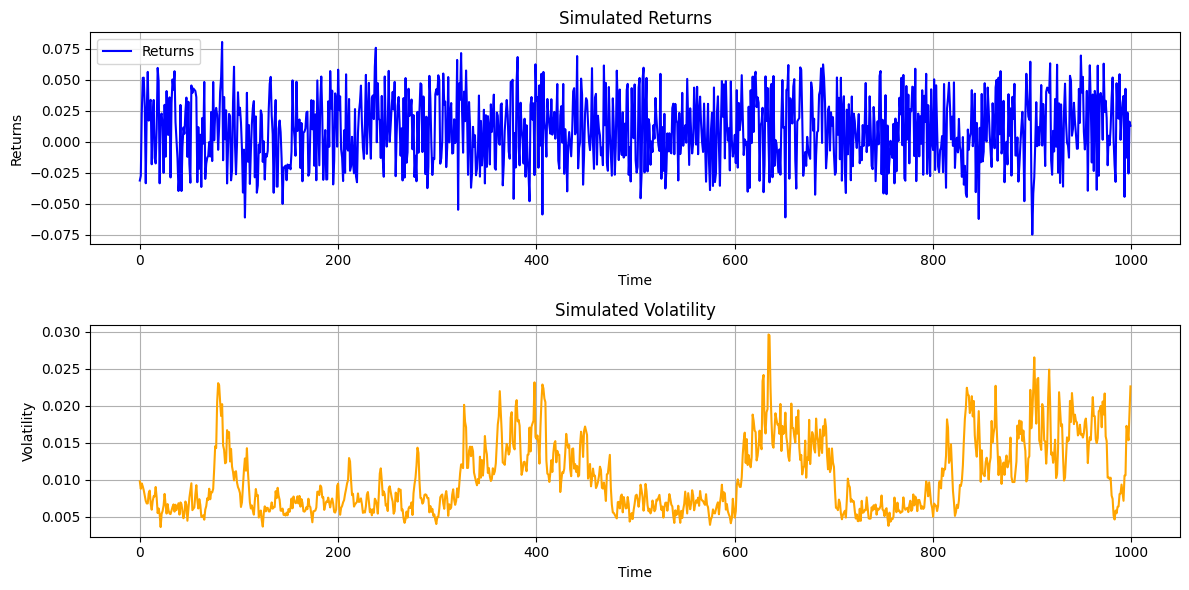

In [376]:
plt.figure(figsize=(12, 6))
plt.subplot(2, 1, 1)
plt.plot(y, label='Returns', color='blue')
plt.title('Simulated Returns')
plt.xlabel('Time')
plt.ylabel('Returns')
plt.legend()
plt.grid()
plt.subplot(2, 1, 2)
plt.plot(np.exp(h/2), label='Volatility', color='orange')
plt.title('Simulated Volatility')
plt.xlabel('Time')
plt.ylabel('Volatility')
plt.grid()
plt.tight_layout()


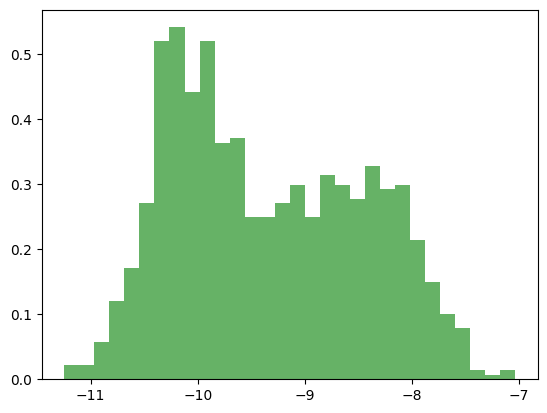

In [377]:
plt.hist(h, bins=30, density=True, alpha=0.6, color='g')
plt.show()

### Bootstrap filter

1) Initialisation :
    - On initialise un vecteur de poids (taille M), d'increments(T), de volatilité (T) et on initialise les particules suivant une loi normale de moyenne -9.25 et d'écart type sigma (M).

2) Boucle $t=0,...,T$ :
    - Propagation : Chaque particule avance selon la transition : $\tilde{h_t}^{(i)} = m_h(h_{t-1}^{(i)}) + \sigma w_t$.
    - Poids (log) : Pour chaque particule, on calcule $log(p(y_t | \tilde{h_t}^{(i)}))$. On sait que $y_t = \alpha + \exp(h_t/2) v_t$ donc $\mathbb{E}(y_t | h_t) = \alpha$. 
    $Var(y_t | h_t) = \exp(h_t)$. Donc $p(y_t | h_t) = \dfrac{1}{\sqrt{2\pi e^{h_t}}} \exp(-\frac{(y_t - \alpha)^2}{2e^{h_t}}) $
    - Incréments de vraisemblance : $p(y_t | y_{1:t−1}) ≈ (1/M) Σ_i w_t⁽ⁱ⁾$ (on passe en log dans le code). C'est la densité de l'observation du jour. Cela mesure à quel point le model s'attendait-il au rendement observé aujourd'hui. Dans le code on utilise un trick pour ne pas qu'on ai d'overflow : on soustrait par le poids maximum dans l'exponentielle et on l'additionne en dehors du log car l'exponentielle ne peut pas calculer des valeurs avec de gros exposants, même si le resultat finale est petit.
    - Normalisation des poids : On divise chaque poids par la somme des poids (softmax). On utilise le même trick du max pour ne pas avoir d'overflow si on a des poids avec de grosses valeurs.
    - Réechantillonnage : On tire M particules selon les poids et on remplace les particules par les particules selectionnées qui repartent toutes avec un poids 1/M.
    - On stocke notre volatilité prédite comme la moyenne des particules après réechantillonnage

On calcule la log likelihood comme la somme des incréments : $p(y_1, …, y_T) = p(y_1) × p(y_2 | y_1) × p(y_3 | y_1, y_2) × … × p(y_T | y_1, …, y_{T−1})$

In [378]:
def bootstrap_filter(y, x, alpha, beta, sigma_w, initial_mean, initial_std, m_h:callable, M):
    T = len(y)
    weights = np.zeros(M)
    increments = np.zeros(T)
    h=np.zeros(T)
    particles = np.random.normal(initial_mean, initial_std, size=M)
    for t in range(T):
        particles = m_h(h_prev=particles) + np.random.normal(0, sigma_w, size=M)
        weights = -0.5*np.log(2*np.pi) -0.5*particles - (y[t] - alpha - beta*x[t])**2 / (2*np.exp(particles))
        increments[t] = np.log(np.sum(np.exp(weights - np.max(weights)))) +  np.max(weights) - np.log(M)
        weights = np.exp(weights - np.max(weights))/np.sum(np.exp(weights - np.max(weights)))
        particles = np.random.choice(particles, size=M, p=weights)
        h[t] = np.mean(particles)
    log_likelihood = np.sum(increments)
    return log_likelihood, increments, h

log_likelihood, increments, h_hat = bootstrap_filter(y, x, alpha=0.01, beta=0.9, sigma_w=0.25,initial_mean=-9.25, initial_std=0.7, m_h=mh_simu, M=1000)
print(f"Log likelihood: {log_likelihood}")
print(f"MSE between true h and estimated h_hat: {np.mean((h - h_hat)**2)}")
  

Log likelihood: 3169.7555328038616
MSE between true h and estimated h_hat: 0.43159967396338583


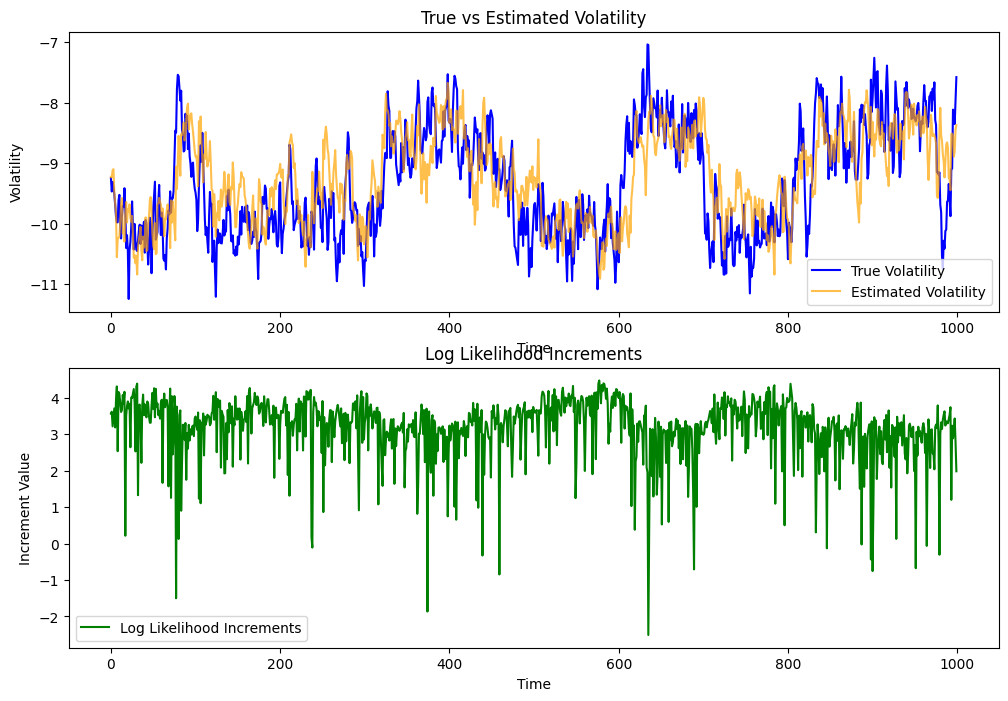

In [379]:
plt.figure(figsize=(12, 8))
plt.subplot(2, 1, 1)
plt.plot(h, label='True Volatility', color='blue')
plt.plot(h_hat, label='Estimated Volatility', color='orange', alpha=0.7)
plt.title('True vs Estimated Volatility')
plt.xlabel('Time')
plt.ylabel('Volatility')
plt.legend()

plt.subplot(2, 1, 2)
plt.plot(increments, label='Log Likelihood Increments', color='green')
plt.title('Log Likelihood Increments')
plt.xlabel('Time')
plt.ylabel('Increment Value')
plt.legend()
plt.show()

In [380]:
def monte_carlo_noise(n=10, m_h = mh_spline,m_h2 = mh_simu, sigma_w=0.25, initial_mean=-9.25, initial_std=0.7):
    bootstrap_results = []
    for i in range(n):
        y, h, x = data_generating_process(T=1000, sigma_w=sigma_w, mu=initial_mean, phi=initial_std)
        log_likelihood, _, _ = bootstrap_filter(y, x, alpha=0.1, beta=0.9,initial_mean=initial_mean, initial_std=initial_std, sigma_w=sigma_w, m_h=m_h, M=1000)
        log_likelihood2, _, _ = bootstrap_filter(y, x, alpha=0.1, beta=0.9, initial_mean=initial_mean, initial_std=initial_std, sigma_w=sigma_w, m_h=m_h2, M=1000)
        bootstrap_results.append(abs(log_likelihood - log_likelihood2))
    return bootstrap_results, np.mean(bootstrap_results), np.std(bootstrap_results)
monte_carlo_results, mean_diff, std_diff = monte_carlo_noise(n=10)
print(f"Mean difference in log likelihoods: {mean_diff}")
print(f"Standard deviation of differences: {std_diff}")

Mean difference in log likelihoods: 137.46617863407724
Standard deviation of differences: 79.72259804990655


## PMMH SV classique

On initialise nos parametres $\theta = (\alpha, \beta, \mu, \phi, \log(\sigma^2))$. On calcule la vraisemblance en utilisant notre filtre bootstrap sur les parametres initialisés. On pose le prior : $\alpha, \beta, \phi, \log(\sigma^2) \sim \mathcal{N}(0,100)$. Donc le log prior joint est proportionel à $− (α² + β² + μ² + φ² + (log σ²)²) / 200$. 

Pour chaque itération, on ajoute du bruit à nos parametres, et on recalcule la vraisemblance avec le filtre bootstrap, ainsi que le prior.

Le ratio d'acceptation est : $\alpha(\theta^*, \theta) = \min{(\dfrac{p(\theta^*)p(y_t | \theta^*) q(\theta, \theta^*)}{p(\theta)p(y_t | \theta) q(\theta^*, \theta)},1)}$. Or nos $q$ sont des loi normales donc symétrique. On peut donc simplifier notre ratio. On passe en log et on a $\log(\alpha(\theta^*, \theta)) = \log(p(\theta^*))+\log(p(y_t | \theta^*)) - \log(p(\theta))-\log(p(y_t | \theta)) $.

In [389]:
from sklearn.linear_model import LinearRegression

def classical_sv_pmmh(y,x, warmup_iterations=100, iterations=100):
    reg = LinearRegression().fit(x.reshape(-1, 1), y)
    alpha = reg.intercept_
    beta = reg.coef_[0]    
    mu  = 2 * np.log((x*beta + alpha - y).std())
    phi = 0.5
    log_sigma2 = -3

    history = []

    def m_h_init(h_prev):
        return mu*(1-phi) + phi*h_prev
    std = np.sqrt(np.exp(log_sigma2))/np.sqrt(1-phi**2)
    log_likelihood,_,_ = bootstrap_filter(y, x, alpha, beta, initial_mean=mu, initial_std=std, sigma_w=np.sqrt(np.exp(log_sigma2)), m_h=m_h_init, M=1000)
    log_prior = -(alpha**2 + beta**2 + phi**2 + log_sigma2**2 + mu**2)/200


    for iteration in range(warmup_iterations + iterations):
        alpha_hat = np.random.normal(alpha, 0.0003)
        beta_hat = np.random.normal(beta, 0.01)
        phi_hat = np.random.normal(phi, 0.01)
        log_sigma2_hat = np.random.normal(log_sigma2, 0.05)
        mu_hat = np.random.normal(mu, 0.01)
        if abs(phi_hat) >= 1:
            continue
        def m_h_hat(h_prev):
            return mu_hat*(1-phi_hat) + phi_hat*h_prev
        std_hat = np.sqrt(np.exp(log_sigma2_hat))/np.sqrt(1-phi_hat**2)
        new_log_likelihood,_,_ = bootstrap_filter(y, x, alpha_hat, beta_hat, initial_mean=mu_hat, initial_std=std_hat, sigma_w= np.sqrt(np.exp(log_sigma2_hat)), m_h=m_h_hat, M=1000)
        new_log_prior = -(alpha_hat**2 + beta_hat**2 + phi_hat**2 + log_sigma2_hat**2 + mu_hat**2)/200

        log_ratio = new_log_likelihood + new_log_prior - log_likelihood - log_prior
        if np.log(np.random.rand()) < log_ratio :
            log_likelihood, log_prior = new_log_likelihood, new_log_prior
            
            alpha, beta, phi, log_sigma2, mu = alpha_hat, beta_hat, phi_hat, log_sigma2_hat, mu_hat
        history.append([alpha, beta, phi, log_sigma2, mu, log_likelihood, log_prior])
        if iteration % 100 == 0:
            print(f"Iteration {iteration + 1}: Log likelihood = {log_likelihood}, alpha = {alpha}, beta = {beta}, sigma = {np.sqrt(np.exp(log_sigma2))}, phi = {phi}")
    history = np.array(history)
    posterior = history[warmup_iterations:] 
    alpha, beta, phi, log_sigma2, mu = np.mean(posterior[:, 0], axis=0), np.mean(posterior[:, 1], axis=0), np.mean(posterior[:, 2], axis=0), np.mean(posterior[:, 3], axis=0), np.mean(posterior[:, 4], axis=0)
    _,_,h_hat = bootstrap_filter(y, x, alpha, beta, initial_mean=mu, initial_std=np.sqrt(np.exp(log_sigma2))/np.sqrt(1-phi**2), sigma_w=np.sqrt(np.exp(log_sigma2)), m_h=lambda h_prev: mu*(1-phi) + phi*h_prev, M=1000)
    return (alpha, beta, phi, np.sqrt(np.exp(log_sigma2)), mu),h_hat, history
parameters, h_hat, history = classical_sv_pmmh(y,x, warmup_iterations=500, iterations=500)
    

Iteration 1: Log likelihood = 3127.049848276546, alpha = 0.010265680369275231, beta = 0.8837249525349237, sigma = 0.23114870681200636, phi = 0.5043683009644376
Iteration 101: Log likelihood = 3157.594767929628, alpha = 0.009926437433241996, beta = 0.9161644903835153, sigma = 0.4171789033692142, phi = 0.6565163877333012
Iteration 201: Log likelihood = 3192.0402525031614, alpha = 0.010318763433062077, beta = 0.8843134962244524, sigma = 0.42696256315349457, phi = 0.8301694922483871
Iteration 301: Log likelihood = 3196.4176459200116, alpha = 0.009693687705175707, beta = 0.8807462357076208, sigma = 0.4056898861142876, phi = 0.8920592418145832
Iteration 401: Log likelihood = 3199.617639473763, alpha = 0.010580735922084984, beta = 0.8667673452666924, sigma = 0.2941788149518552, phi = 0.9385757234281201
Iteration 501: Log likelihood = 3205.8006013064723, alpha = 0.010364125318519032, beta = 0.8852236153807878, sigma = 0.22881203030943126, phi = 0.9583658971246274
Iteration 601: Log likelihood 

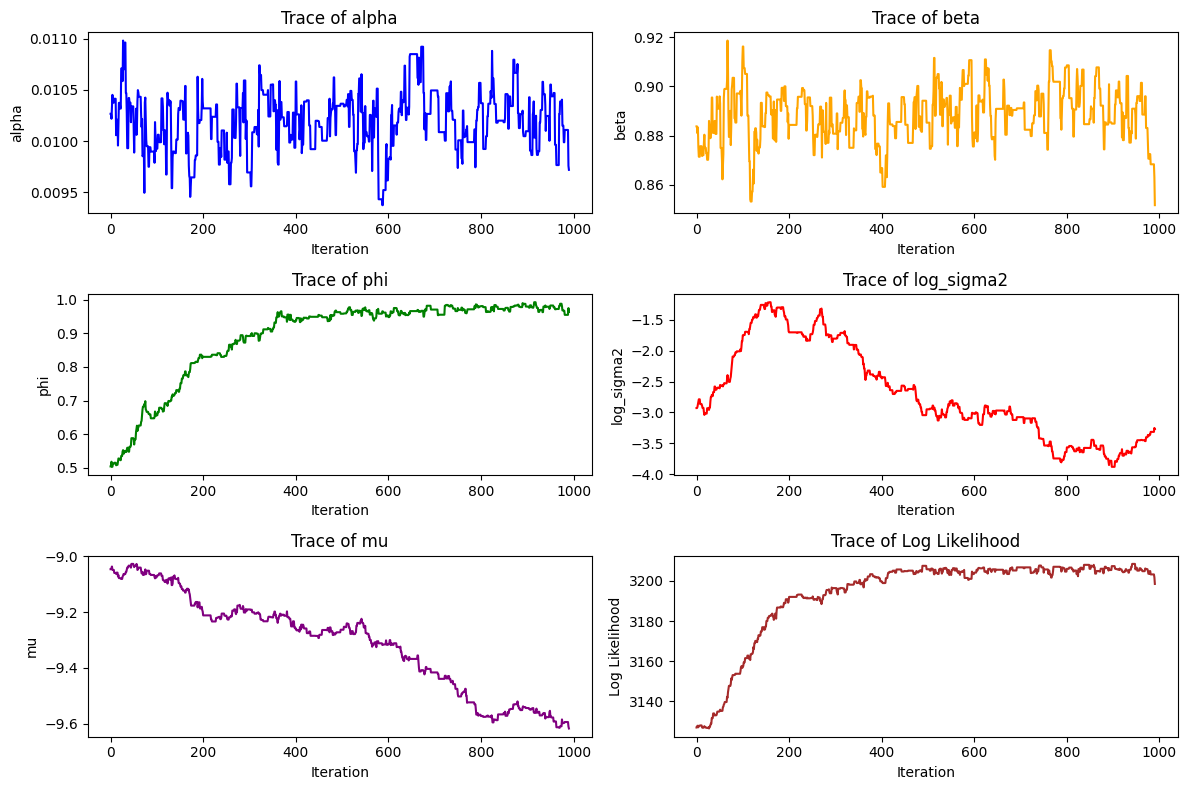

In [390]:
plt.figure(figsize=(12, 8))
plt.subplot(3, 2, 1)
plt.plot([h[0] for h in history], label='alpha', color='blue')
plt.title('Trace of alpha')
plt.xlabel('Iteration')
plt.ylabel('alpha')
plt.subplot(3, 2, 2)
plt.plot([h[1] for h in history], label='beta', color='orange')
plt.title('Trace of beta')
plt.xlabel('Iteration')
plt.ylabel('beta')
plt.subplot(3, 2, 3)
plt.plot([h[2] for h in history], label='phi', color='green')
plt.title('Trace of phi')
plt.xlabel('Iteration')
plt.ylabel('phi')
plt.subplot(3, 2, 4)
plt.plot([h[3] for h in history], label='log_sigma2', color='red')
plt.title('Trace of log_sigma2')
plt.xlabel('Iteration')
plt.ylabel('log_sigma2')
plt.subplot(3, 2, 5)
plt.plot([h[4] for h in history], label='mu', color='purple')
plt.title('Trace of mu')
plt.xlabel('Iteration')
plt.ylabel('mu')
plt.subplot(3, 2, 6)
plt.plot([h[5] for h in history], label='Log Likelihood', color='brown')
plt.title('Trace of Log Likelihood')
plt.xlabel('Iteration')
plt.ylabel('Log Likelihood')
plt.tight_layout()

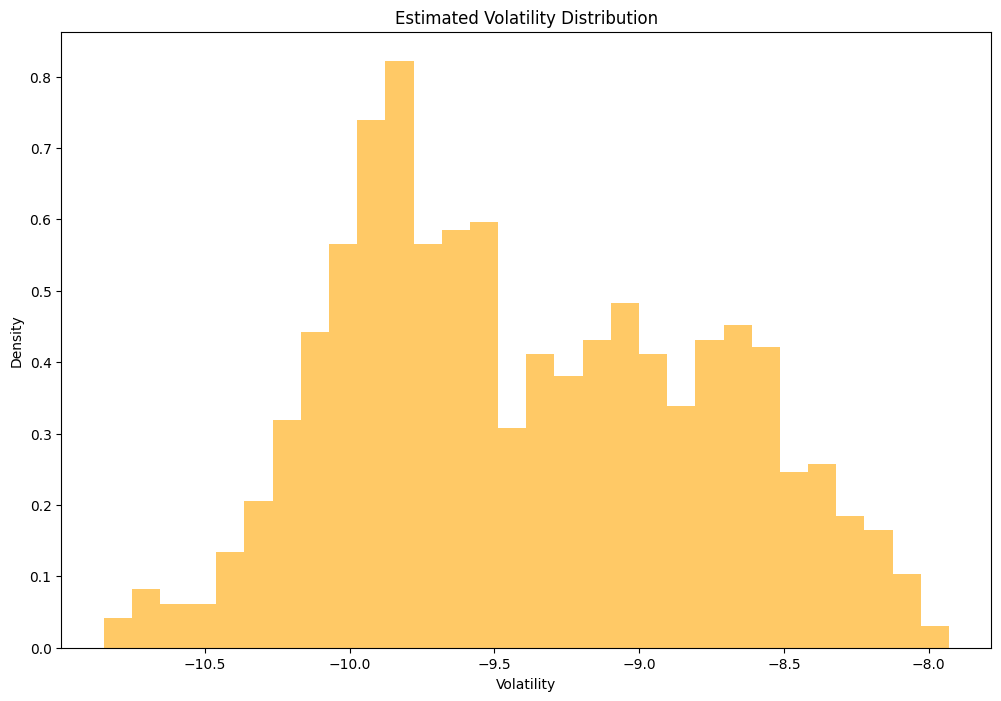

In [391]:
plt.figure(figsize=(12, 8))
plt.hist(h_hat, label='Estimated Volatility', color='orange', bins=30, density=True, alpha=0.6)
plt.title('Estimated Volatility Distribution')
plt.xlabel('Volatility')
plt.ylabel('Density')
plt.show()

In [ ]:
def parametric_sv_pmmh(y,x, K=6,sigma_e=0.01, warmup_iterations=1000, iterations=1000):
    print("Initializing using classical SV PMMH...")
    parameters,h_hat, _,  = classical_sv_pmmh(y,x, warmup_iterations=500, iterations=200)
    
    a,b = np.quantile(h_hat, [0.01, 0.99])
    knots = np.linspace(a, b, K+1)
    K_penalty = K_gen(knots)
    eigenvalues, eigenvectors = np.linalg.eigh(K_penalty)
    g = parameters[4]*(1-parameters[2]) + parameters[2]*knots
    alpha, beta, log_sigma2 = parameters[0], parameters[1], np.log(parameters[3]**2)
    initial_mean = parameters[4]
    initial_std = np.sqrt(np.exp(log_sigma2))/np.sqrt(1-parameters[2]**2)
    lamb = 0.01
    log_prior = -(alpha**2 + beta**2 + log_sigma2**2)/200 - 0.5*lamb*g.T @ K_penalty @ g
    
    spline_func = CubicSpline(knots, g, bc_type='natural')
    m_h = lambda h_prev: spline(spline_func, knots, h_prev)
    log_likelihood,_,_ = bootstrap_filter(y, x, alpha, beta, initial_mean=initial_mean, initial_std=initial_std, sigma_w=np.sqrt(np.exp(log_sigma2)), m_h=m_h, M=1000)
    history, g_history = [], []
    accept_count = 0
    accept_count_g = 0
    print(f"Initial Log likelihood = {log_likelihood}, alpha = {alpha}, beta = {beta}, sigma = {np.sqrt(np.exp(log_sigma2))}")
    for iteration in range(warmup_iterations + iterations):
        alpha_hat = np.random.normal(alpha, 0.0003)
        beta_hat = np.random.normal(beta, 0.01)
        log_sigma2_hat = np.random.normal(log_sigma2, 0.05)

        m_h_hat = lambda h_prev: spline(spline_func, knots, h_prev)
        log_prior_hat = -(alpha_hat**2 + beta_hat**2 + log_sigma2_hat**2)/200 - 0.5*lamb*g.T @ K_penalty @ g
        new_log_likelihood,_,_ = bootstrap_filter(y, x, alpha_hat, beta_hat, initial_mean=initial_mean, initial_std=initial_std, sigma_w=np.sqrt(np.exp(log_sigma2_hat)), m_h=m_h_hat, M=1000)
        log_ratio = new_log_likelihood + log_prior_hat - log_likelihood - log_prior
        if np.log(np.random.rand()) < log_ratio :
            log_likelihood, log_prior = new_log_likelihood, log_prior_hat
            alpha, beta, log_sigma2 = alpha_hat, beta_hat, log_sigma2_hat
            accept_count += 1


        coeff = np.random.normal(0, 1, K+1)
        eps = np.zeros(K+1)
        for i in range(K+1):
            if i<=1:
                eps += eigenvectors[:,i]*coeff[i]*0.01
            else:
                eps += eigenvectors[:,i]*coeff[i]*sigma_e/np.sqrt(eigenvalues[i])
        g_hat = g + eps
        log_prior_hat = -(alpha**2 + beta**2 + log_sigma2**2)/200 - 0.5*lamb*g_hat.T @ K_penalty @ g_hat
        
        spline_func_hat = CubicSpline(knots, g_hat, bc_type='natural')
        m_h_hat = lambda h_prev: spline(spline_func_hat, knots, h_prev)
        new_log_likelihood,_,_ = bootstrap_filter(y, x, alpha, beta, initial_mean=initial_mean, initial_std=initial_std, sigma_w=np.sqrt(np.exp(log_sigma2)), m_h=m_h_hat, M=1000)
        log_ratio = new_log_likelihood + log_prior_hat - log_likelihood - log_prior
        if np.log(np.random.rand()) < log_ratio :
            log_likelihood, log_prior = new_log_likelihood, log_prior_hat
            g = g_hat
            spline_func = spline_func_hat
            accept_count_g += 1
        g_history.append(g)
        history.append([alpha, beta, log_sigma2, log_likelihood, log_prior])
        if iteration % 100 == 0:
            print(f"Iteration {iteration + 1}: Log likelihood = {log_likelihood}, alpha = {alpha}, beta = {beta}, sigma = {np.sqrt(np.exp(log_sigma2))}")
    history = np.array(history)
    posterior = history[warmup_iterations:]
    g_history = np.array(g_history)

    alpha, beta, log_sigma2, g = np.mean(posterior[:, 0], axis=0), np.mean(posterior[:, 1], axis=0), np.mean(posterior[:, 2], axis=0), np.mean(g_history[warmup_iterations:], axis=0)
    _,_,h_hat = bootstrap_filter(y, x, alpha, beta, initial_mean=initial_mean, initial_std=initial_std, sigma_w=np.sqrt(np.exp(log_sigma2)), m_h=lambda h_prev: spline(CubicSpline(knots, g, bc_type='natural'), knots, h_prev), M=1000)
    return (alpha, beta, np.sqrt(np.exp(log_sigma2)), g), h_hat, history, (accept_count/(iterations+warmup_iterations), accept_count_g/(iterations+warmup_iterations))
parameters, h_hat, history, rates= parametric_sv_pmmh(y,x, sigma_e=0.1, warmup_iterations=500, iterations=500)

Initializing using classical SV PMMH...
Iteration 1: Log likelihood = 3127.2920180983783, alpha = 0.010039085858212983, beta = 0.8916988957214217, sigma = 0.22313016014842985, phi = 0.5
Iteration 101: Log likelihood = 3156.4743120407306, alpha = 0.00946316449613215, beta = 0.908575936923998, sigma = 0.3310359271242563, phi = 0.7235604090724048
Iteration 201: Log likelihood = 3196.007642430313, alpha = 0.010588698734938187, beta = 0.8891327545960935, sigma = 0.37894070474298774, phi = 0.919435095379758
